# Segundo Modelo de Predicción con Regresión Lineal (SIMPLE)

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [6]:
# Configuración
np.random.seed(42)
plt.style.use('default')

Datos generados: 50 muestras
x: [0.21, 9.70]
y: [2.87, 29.85]


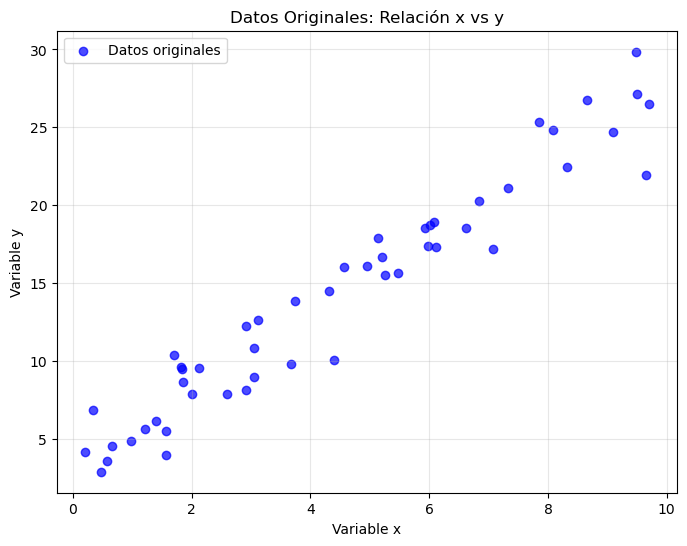

In [8]:
n_muestras = 50
x = np.random.uniform(0, 10, n_muestras)
y = 2.5 * x + 3 + np.random.normal(0, 2, n_muestras)  # y = 2.5x + 3 + ruido

print(f"Datos generados: {n_muestras} muestras")
print(f"x: [{x.min():.2f}, {x.max():.2f}]")
print(f"y: [{y.min():.2f}, {y.max():.2f}]")


# ## 2. Gráfica de los Datos Originales


plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7, color='blue', label='Datos originales')
plt.title('Datos Originales: Relación x vs y')
plt.xlabel('Variable x')
plt.ylabel('Variable y')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [10]:
# Preparar datos para sklearn (necesita matriz 2D)
X = x.reshape(-1, 1)  # Convertir a matriz columna

# Crear y entrenar modelo
modelo = LinearRegression()
modelo.fit(X, y)

# Obtener parámetros del modelo
beta_0 = modelo.intercept_
beta_1 = modelo.coef_[0]

print("MODELO DE REGRESIÓN LINEAL ENTRENADO:")
print("=" * 40)
print(f"Ecuación: y = {beta_1:.4f} * x + {beta_0:.4f}")
print(f"Parámetros aprendidos: β₀ = {beta_0:.4f}, β₁ = {beta_1:.4f}")
print(f"Parámetros reales: β₀ = 3.0000, β₁ = 2.5000")

MODELO DE REGRESIÓN LINEAL ENTRENADO:
Ecuación: y = 2.4553 * x + 3.1934
Parámetros aprendidos: β₀ = 3.1934, β₁ = 2.4553
Parámetros reales: β₀ = 3.0000, β₁ = 2.5000


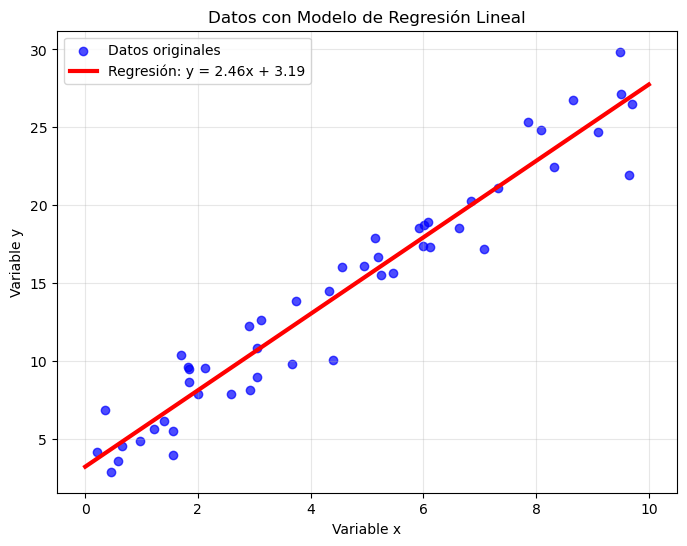

In [12]:
# Crear valores para la línea de regresión
x_line = np.linspace(0, 10, 100).reshape(-1, 1)
y_line = modelo.predict(x_line)

plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7, color='blue', label='Datos originales')
plt.plot(x_line, y_line, 'r-', linewidth=3, label=f'Regresión: y = {beta_1:.2f}x + {beta_0:.2f}')
plt.title('Datos con Modelo de Regresión Lineal')
plt.xlabel('Variable x')
plt.ylabel('Variable y')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [16]:
# Valores nuevos para predecir
nuevos_x = np.array([11, 11.5, 12, 12.5, 13]).reshape(-1, 1)
predicciones = modelo.predict(nuevos_x)

print("PREDICCIONES EN DATOS NO VISTOS:")
print("=" * 40)
for x_val, y_pred in zip(nuevos_x.flatten(), predicciones):
    y_real = 2.5 * x_val + 3  # Valor real (sin ruido)
    error = abs(y_pred - y_real)
    print(f"x = {x_val:5.1f} → ŷ = {y_pred:6.2f} (Real: {y_real:6.2f}, Error: {error:5.2f})")

PREDICCIONES EN DATOS NO VISTOS:
x =  11.0 → ŷ =  30.20 (Real:  30.50, Error:  0.30)
x =  11.5 → ŷ =  31.43 (Real:  31.75, Error:  0.32)
x =  12.0 → ŷ =  32.66 (Real:  33.00, Error:  0.34)
x =  12.5 → ŷ =  33.88 (Real:  34.25, Error:  0.37)
x =  13.0 → ŷ =  35.11 (Real:  35.50, Error:  0.39)


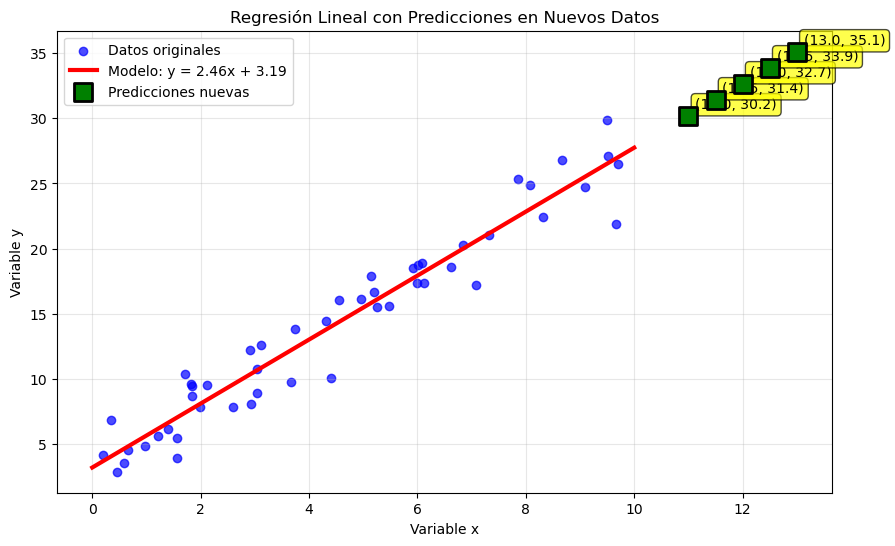

In [18]:
plt.figure(figsize=(10, 6))

# Datos originales y modelo
plt.scatter(x, y, alpha=0.7, color='blue', label='Datos originales')
plt.plot(x_line, y_line, 'r-', linewidth=3, label=f'Modelo: y = {beta_1:.2f}x + {beta_0:.2f}')

# Predicciones en nuevos puntos
plt.scatter(nuevos_x, predicciones, color='green', s=150, marker='s', 
           edgecolors='black', linewidth=2, zorder=5, label='Predicciones nuevas')

# Añadir etiquetas a las predicciones
for x_val, y_pred in zip(nuevos_x.flatten(), predicciones):
    plt.annotate(f'({x_val}, {y_pred:.1f})', 
                (x_val, y_pred), 
                xytext=(5, 5), 
                textcoords='offset points',
                fontsize=10,
                bbox=dict(boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.7))

plt.title('Regresión Lineal con Predicciones en Nuevos Datos')
plt.xlabel('Variable x')
plt.ylabel('Variable y')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [20]:
print("RESUMEN DEL MODELO:")
print("=" * 40)
print(f"1. Ecuación aprendida: y = {beta_1:.4f}x + {beta_0:.4f}")
print(f"2. Error promedio en predicciones nuevas: {np.mean(np.abs(predicciones - (2.5*nuevos_x.flatten() + 3))):.4f}")
print(f"3. El modelo puede extrapolar fuera del rango de entrenamiento [0, 10]")
print(f"4. Interpretación: Por cada unidad que aumenta x, y aumenta {beta_1:.2f} unidades")

RESUMEN DEL MODELO:
1. Ecuación aprendida: y = 2.4553x + 3.1934
2. Error promedio en predicciones nuevas: 0.3429
3. El modelo puede extrapolar fuera del rango de entrenamiento [0, 10]
4. Interpretación: Por cada unidad que aumenta x, y aumenta 2.46 unidades


In [22]:
# Código para usar el modelo en producción
def predecir_y(valores_x, modelo):
    """Función para hacer predicciones con nuevos valores de x"""
    if isinstance(valores_x, (int, float)):
        valores_x = [[valores_x]]
    predicciones = modelo.predict(valores_x)
    return predicciones

# Ejemplo de uso
print("\nEJEMPLO DE USO DEL MODELO:")
valor_ejemplo = 7.5
prediccion = predecir_y(valor_ejemplo, modelo)[0]
print(f"Para x = {valor_ejemplo}, la predicción es ŷ = {prediccion:.2f}")
print(f"Valor esperado (y = 2.5x + 3): {2.5*valor_ejemplo + 3:.2f}")


EJEMPLO DE USO DEL MODELO:
Para x = 7.5, la predicción es ŷ = 21.61
Valor esperado (y = 2.5x + 3): 21.75


# Ejemplo Real

## Análisis de la Concentración de CO2

Esta sección se centra en la visualización y el análisis de la concentración anual de CO₂ en la atmósfera utilizando datos de 2006 a 2013.

Primero, se carga un conjunto de datos simple que contiene el año y la concentración de CO₂, y se crea un DataFrame de pandas.

Luego, se genera un gráfico de líneas para observar la tendencia de la concentración de CO₂ a lo largo del tiempo, con marcadores para cada punto de datos y personalizaciones visuales para mejorar la legibilidad.

Finalmente, se calcula y grafica una recta de tendencia lineal entre dos puntos específicos (2006 y 2010) para fines comparativos con los datos reales. Se calcula la pendiente y la ordenada al origen de esta recta manualmente y se superpone en el gráfico de los datos originales.

In [28]:
import pandas as pd

# Datos de concentración anual de CO₂
data = {
    'Año': [2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013],
    'Concentración de CO2 (ppm)': [381.90, 383.76, 385.59, 387.37, 389.85, 391.63, 393.82, 396.48]
}

# 1. Creando el DataFrame
df = pd.DataFrame(data)

# Imprimiendo el DataFrame para verificar que los datos están cargados
print(df)

    Año  Concentración de CO2 (ppm)
0  2006                      381.90
1  2007                      383.76
2  2008                      385.59
3  2009                      387.37
4  2010                      389.85
5  2011                      391.63
6  2012                      393.82
7  2013                      396.48


In [30]:
# 2. Creando un DataFrame de pandas
df = pd.DataFrame(data)

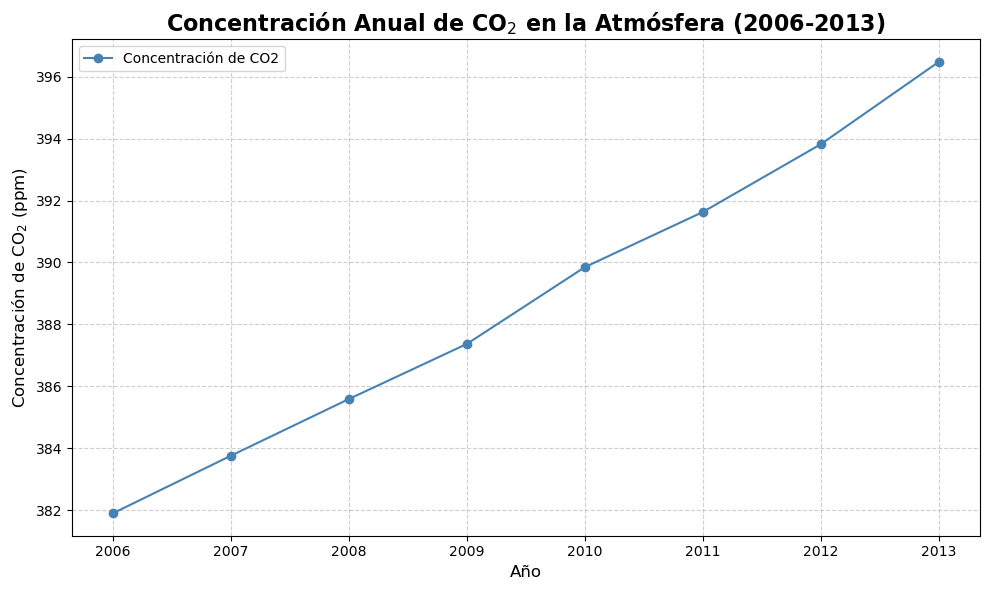

In [38]:
# 3. Creando el gráfico de líneas
plt.figure(figsize=(10, 6)) # Define el tamaño de la figura para una mejor visualización

# Grafica los datos. El eje X es el 'Año' y el eje Y es la 'Concentración'
plt.plot(df['Año'], df['Concentración de CO2 (ppm)'],
         marker='o',          # Añade marcadores circulares en cada punto de datos
         linestyle='-',       # Conecta los puntos con una línea sólida
         color='steelblue',   # Color de la línea y los marcadores
         label='Concentración de CO2') # Etiqueta para la leyenda

# 4. Personalizando el gráfico
plt.title('Concentración Anual de CO$_2$ en la Atmósfera (2006-2013)',
          fontsize=16,
          fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('Concentración de CO$_2$ (ppm)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6) # Añade una cuadrícula para facilitar la lectura
plt.xticks(df['Año']) # Muestra todos los años en el eje X

# 5. Añadiendo una leyenda y mostrando el gráfico
plt.legend()
plt.tight_layout() # Ajusta el diseño para que no haya superposiciones
plt.show()

# Modelo propuesto por un humano

## Veamos como seria una propuesta de modelo de regresión lineal simple sin usar LinearRegression() de la libreria, sino matematicas elementales

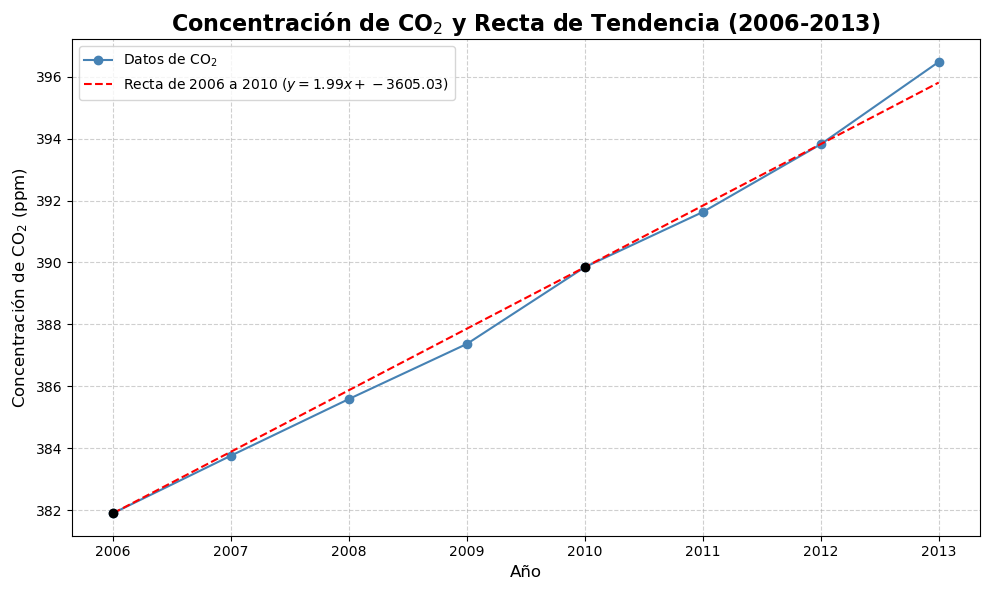

In [40]:
# 2. Seleccionar los datos de los años 2006 y 2010
x1 = df[df['Año'] == 2006]['Año'].values[0]
y1 = df[df['Año'] == 2006]['Concentración de CO2 (ppm)'].values[0]

x2 = df[df['Año'] == 2010]['Año'].values[0]
y2 = df[df['Año'] == 2010]['Concentración de CO2 (ppm)'].values[0]

# 3. Calcular la pendiente (m) y la ordenada al origen (b) de la recta
# Pendiente (m) = (y2 - y1) / (x2 - x1)
m = (y2 - y1) / (x2 - x1)

# Ordenada al origen (b) = y1 - m * x1
b = y1 - m * x1

# 4. Crear los valores para graficar la recta
# np.linspace() crea un rango de valores desde el primer año hasta el último
x_recta = np.linspace(df['Año'].min(), df['Año'].max(), 100)
y_recta = m * x_recta + b

# 5. Graficar los datos originales y la recta en el mismo plot
plt.figure(figsize=(10, 6))

# Gráfico de los datos de CO2 (puntos azules)
plt.plot(df['Año'], df['Concentración de CO2 (ppm)'],
         marker='o',
         linestyle='-',
         color='steelblue',
         label='Datos de CO$_2$')

# Gráfico de la recta de regresión (línea roja)
plt.plot(x_recta, y_recta,
         linestyle='--',
         color='red',
         label=f'Recta de 2006 a 2010 ($y = {m:.2f}x + {b:.2f}$)')

# Destacar los puntos de referencia
plt.scatter([x1, x2], [y1, y2], color='black', zorder=5)

# Personalización del gráfico
plt.title('Concentración de CO$_2$ y Recta de Tendencia (2006-2013)',
          fontsize=16,
          fontweight='bold')
plt.xlabel('Año', fontsize=12)
plt.ylabel('Concentración de CO$_2$ (ppm)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df['Año'])

# Añadir la leyenda y mostrar el gráfico
plt.legend()
plt.tight_layout()
plt.show()